In [3]:
!pip -q install kagglehub scikit-image seaborn

In [4]:
import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

from skimage.feature import hog, local_binary_pattern
from skimage.feature import graycomatrix, graycoprops

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
import kagglehub

path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print("Dataset downloaded to:")
print(path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset downloaded to:
/kaggle/input/chest-xray-pneumonia


In [6]:
import os

for root, dirs, files in os.walk(path):
    if "train" in dirs or "test" in dirs or "val" in dirs:
        print(root)
        print("Folders:", dirs)

/kaggle/input/chest-xray-pneumonia/chest_xray
Folders: ['chest_xray', '__MACOSX', 'val', 'test', 'train']
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray
Folders: ['val', 'test', 'train']
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray
Folders: ['val', 'test', 'train']


In [7]:
DATA_DIR = None

for root, dirs, files in os.walk(path):
    if "train" in dirs and "test" in dirs:
        DATA_DIR = root
        break

print("DATASET DIRECTORY:")
print(DATA_DIR)

DATASET DIRECTORY:
/kaggle/input/chest-xray-pneumonia/chest_xray


In [8]:
for split in ["train", "test", "val"]:
    print("\n", split.upper())

    split_path = os.path.join(DATA_DIR, split)

    if os.path.exists(split_path):
        for cls in ["NORMAL", "PNEUMONIA"]:
            class_path = os.path.join(split_path, cls)

            if os.path.exists(class_path):
                count = len(glob.glob(os.path.join(class_path, "*")))
                print(cls, ":", count)


 TRAIN
NORMAL : 1341
PNEUMONIA : 3875

 TEST
NORMAL : 234
PNEUMONIA : 390

 VAL
NORMAL : 8
PNEUMONIA : 8


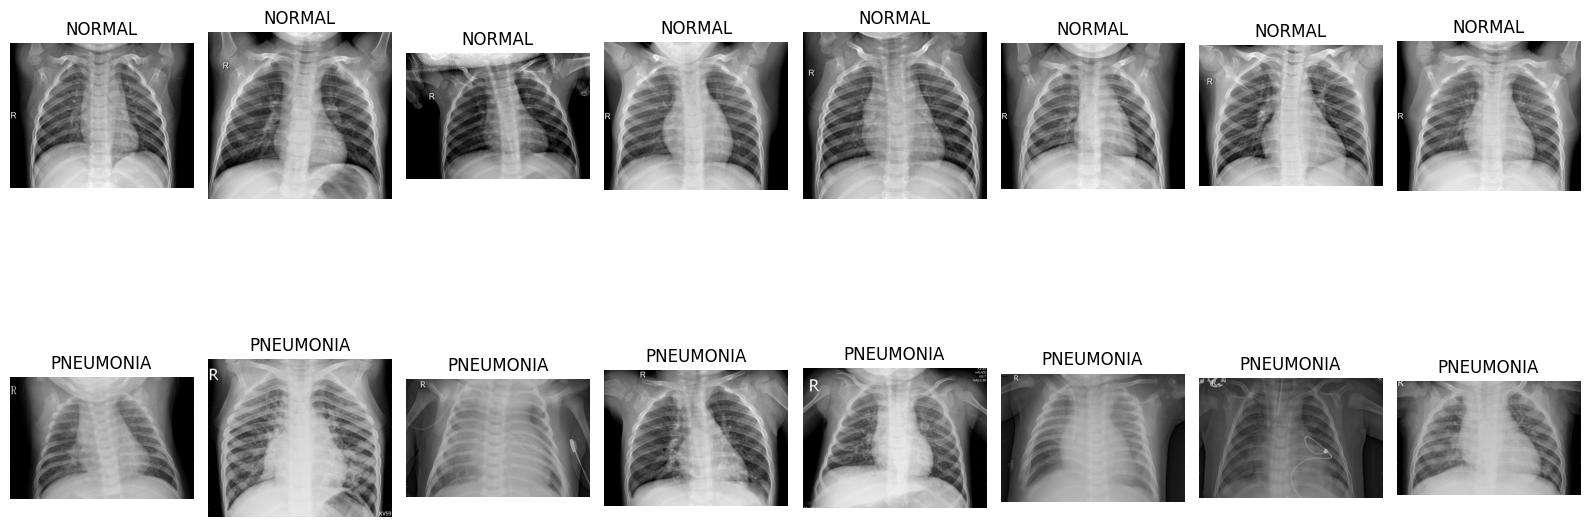

In [9]:
classes = ["NORMAL", "PNEUMONIA"]

plt.figure(figsize=(16, 8))

plot_index = 1

for cls in classes:

    folder = os.path.join(DATA_DIR, "train", cls)

    images = glob.glob(os.path.join(folder, "*"))
    samples = random.sample(images, min(8, len(images)))

    for img_path in samples:

        img = Image.open(img_path).convert("L")

        plt.subplot(2, 8, plot_index)
        plt.imshow(img, cmap="gray")
        plt.title(cls)
        plt.axis("off")

        plot_index += 1

plt.tight_layout()
plt.show()

In [10]:
data = []

for split in ["train", "test", "val"]:

    split_path = os.path.join(DATA_DIR, split)

    if not os.path.exists(split_path):
        continue

    for label, cls in enumerate(["NORMAL", "PNEUMONIA"]):

        class_path = os.path.join(split_path, cls)

        for img_path in glob.glob(os.path.join(class_path, "*")):

            data.append({
                "path": img_path,
                "label": label,
                "class": cls,
                "split": split
            })

df = pd.DataFrame(data)

print("Total images:", len(df))
print("\nClass distribution:")
print(df["class"].value_counts())

df.head()

Total images: 5856

Class distribution:
class
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64


,path,label,class,split
0,/kaggle/input/chest-xray-pneumonia/chest_xray/...,0,NORMAL,train
1,/kaggle/input/chest-xray-pneumonia/chest_xray/...,0,NORMAL,train
2,/kaggle/input/chest-xray-pneumonia/chest_xray/...,0,NORMAL,train
3,/kaggle/input/chest-xray-pneumonia/chest_xray/...,0,NORMAL,train
4,/kaggle/input/chest-xray-pneumonia/chest_xray/...,0,NORMAL,train


In [11]:
IMG_SIZE = 128

def preprocess_image(path):

    img = Image.open(path).convert("L")
    img = img.resize((IMG_SIZE, IMG_SIZE))

    img = np.array(img) / 255.0

    return img

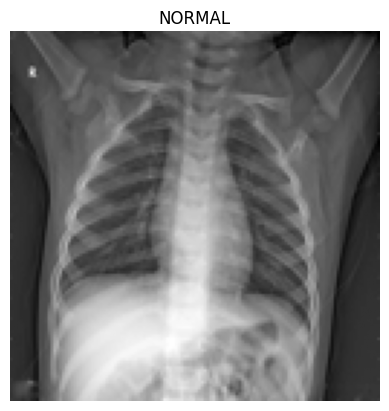

(128, 128)


In [12]:
sample_img = preprocess_image(df.iloc[0]["path"])

plt.imshow(sample_img, cmap="gray")
plt.title(df.iloc[0]["class"])
plt.axis("off")
plt.show()

print(sample_img.shape)

In [13]:
def extract_hog(img):

    features = hog(
        img,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

    return features

In [14]:
def extract_lbp(img):

    img_uint8 = (img * 255).astype(np.uint8)

    radius = 1
    points = 8 * radius

    lbp = local_binary_pattern(
        img_uint8,
        points,
        radius,
        method="uniform"
    )

    n_bins = points + 2

    histogram, _ = np.histogram(
        lbp.ravel(),
        bins=n_bins,
        range=(0, n_bins)
    )

    histogram = histogram.astype("float")
    histogram /= (histogram.sum() + 1e-7)

    return histogram

In [15]:
def extract_glcm(img):

    img_uint8 = (img * 255).astype(np.uint8)

    # Reduce levels to make GLCM computation smaller
    img_quantized = (img_uint8 // 32).astype(np.uint8)

    glcm = graycomatrix(
        img_quantized,
        distances=[1],
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
        levels=8,
        symmetric=True,
        normed=True
    )

    properties = [
        "contrast",
        "dissimilarity",
        "homogeneity",
        "energy",
        "correlation",
        "ASM"
    ]

    features = []

    for prop in properties:

        value = graycoprops(glcm, prop)

        features.extend(value.flatten())

    return np.array(features)

In [16]:
feature_data = []

for i, row in df.iterrows():

    img = preprocess_image(row["path"])

    hog_features = extract_hog(img)
    lbp_features = extract_lbp(img)
    glcm_features = extract_glcm(img)

    combined = np.concatenate([
        hog_features,
        lbp_features,
        glcm_features
    ])

    feature_data.append(combined)

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1}/{len(df)} images")

X_features = np.array(feature_data)
y_features = df["label"].values

print("\nFeature matrix shape:", X_features.shape)
print("Labels shape:", y_features.shape)

Processed 500/5856 images
Processed 1000/5856 images
Processed 1500/5856 images
Processed 2000/5856 images
Processed 2500/5856 images
Processed 3000/5856 images
Processed 3500/5856 images
Processed 4000/5856 images
Processed 4500/5856 images
Processed 5000/5856 images
Processed 5500/5856 images

Feature matrix shape: (5856, 8134)
Labels shape: (5856,)


In [17]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X_features,
    y_features,
    test_size=0.30,
    stratify=y_features,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (4099, 8134)
Validation: (878, 8134)
Testing: (879, 8134)


In [18]:
X_images = []
y_images = []

for i, row in df.iterrows():

    img = preprocess_image(row["path"])

    X_images.append(img)
    y_images.append(row["label"])

    if (i + 1) % 500 == 0:
        print(f"Loaded {i + 1}/{len(df)} images")

X_images = np.array(X_images)
y_images = np.array(y_images)

# Add channel dimension
X_images = X_images[..., np.newaxis]

print("Image data shape:", X_images.shape)
print("Labels shape:", y_images.shape)

Loaded 500/5856 images
Loaded 1000/5856 images
Loaded 1500/5856 images
Loaded 2000/5856 images
Loaded 2500/5856 images
Loaded 3000/5856 images
Loaded 3500/5856 images
Loaded 4000/5856 images
Loaded 4500/5856 images
Loaded 5000/5856 images
Loaded 5500/5856 images
Image data shape: (5856, 128, 128, 1)
Labels shape: (5856,)


In [19]:
X_train_img, X_temp_img, y_train_img, y_temp_img = train_test_split(
    X_images,
    y_images,
    test_size=0.30,
    stratify=y_images,
    random_state=42
)

X_val_img, X_test_img, y_val_img, y_test_img = train_test_split(
    X_temp_img,
    y_temp_img,
    test_size=0.50,
    stratify=y_temp_img,
    random_state=42
)

print("Train:", X_train_img.shape)
print("Validation:", X_val_img.shape)
print("Test:", X_test_img.shape)

Train: (4099, 128, 128, 1)
Validation: (878, 128, 128, 1)
Test: (879, 128, 128, 1)


In [20]:
def create_cnn(filters=32, dropout=0.3, learning_rate=0.001):

    model = keras.Sequential([

        layers.Input(shape=(128, 128, 1)),

        layers.Conv2D(filters, (3,3), activation="relu"),
        layers.MaxPooling2D((2,2)),

        layers.Conv2D(filters*2, (3,3), activation="relu"),
        layers.MaxPooling2D((2,2)),

        layers.Conv2D(filters*4, (3,3), activation="relu"),
        layers.MaxPooling2D((2,2)),

        layers.Flatten(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(dropout),

        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [21]:
model = create_cnn()

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,193 (12.60 MB)

 Trainable params: 3,304,193 (12.60 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
history = model.fit(
    X_train_img,
    y_train_img,
    validation_data=(X_val_img, y_val_img),
    epochs=4,
    batch_size=32,
    verbose=1
)

Epoch 1/4
129/129 ━━━━━━━━━━━━━━━━━━━━ 17s 66ms/step - accuracy: 0.8295 - loss: 0.3840 - val_accuracy: 0.9134 - val_loss: 0.2278
Epoch 2/4
129/129 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9288 - loss: 0.1862 - val_accuracy: 0.9317 - val_loss: 0.1784
Epoch 3/4
129/129 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9390 - loss: 0.1604 - val_accuracy: 0.9487 - val_loss: 0.1332
Epoch 4/4
129/129 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9495 - loss: 0.1313 - val_accuracy: 0.8747 - val_loss: 0.2615


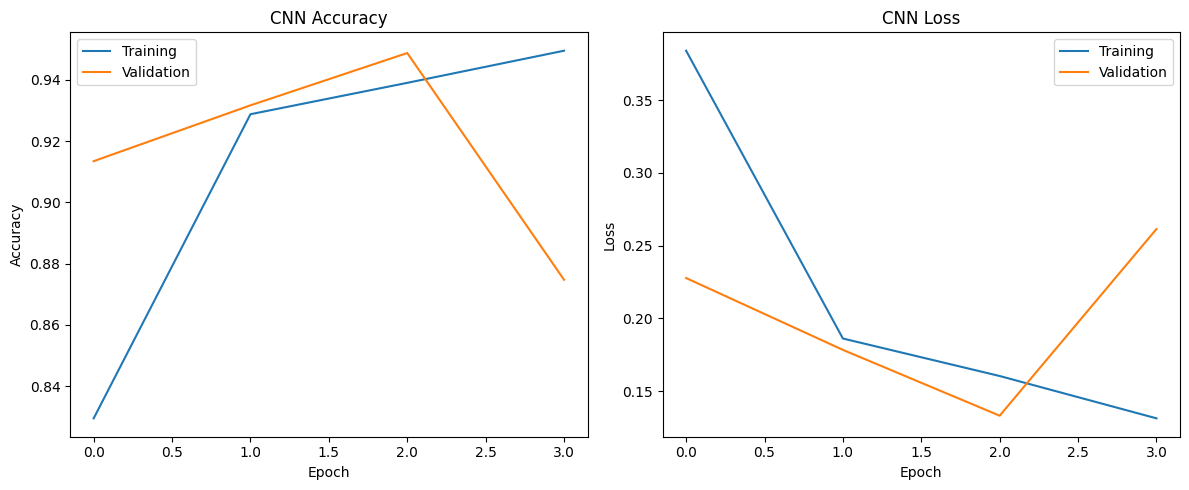

In [23]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


plt.subplot(1,2,2)

plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")

plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [24]:
test_loss, test_accuracy = model.evaluate(
    X_test_img,
    y_test_img,
    verbose=1
)

print("Test Accuracy:", test_accuracy)

28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - accuracy: 0.8680 - loss: 0.2808
Test Accuracy: 0.8680318593978882


In [25]:
y_prob = model.predict(X_test_img).ravel()

y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test_img, y_pred)
precision = precision_score(y_test_img, y_pred)
recall = recall_score(y_test_img, y_pred)
f1 = f1_score(y_test_img, y_pred)
auroc = roc_auc_score(y_test_img, y_prob)

print("========== CNN PERFORMANCE ==========")
print("Accuracy  :", accuracy)
print("Precision :", precision)
print("Recall    :", recall)
print("F1 Score  :", f1)
print("AUROC     :", auroc)

28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step
========== CNN PERFORMANCE ==========
Accuracy  : 0.8680318543799772
Precision : 0.9943502824858758
Recall    : 0.8237129485179407
F1 Score  : 0.9010238907849829
AUROC     : 0.9870803235490764


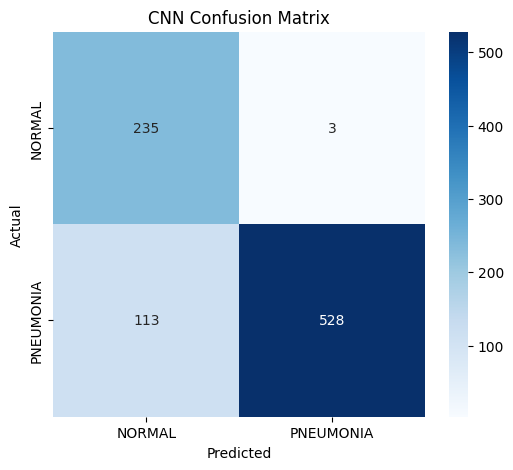

Confusion Matrix:
[[235   3]
 [113 528]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.68      0.99      0.80       238
   PNEUMONIA       0.99      0.82      0.90       641

    accuracy                           0.87       879
   macro avg       0.83      0.91      0.85       879
weighted avg       0.91      0.87      0.87       879



In [26]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test_img, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test_img,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

Misclassified images: 116


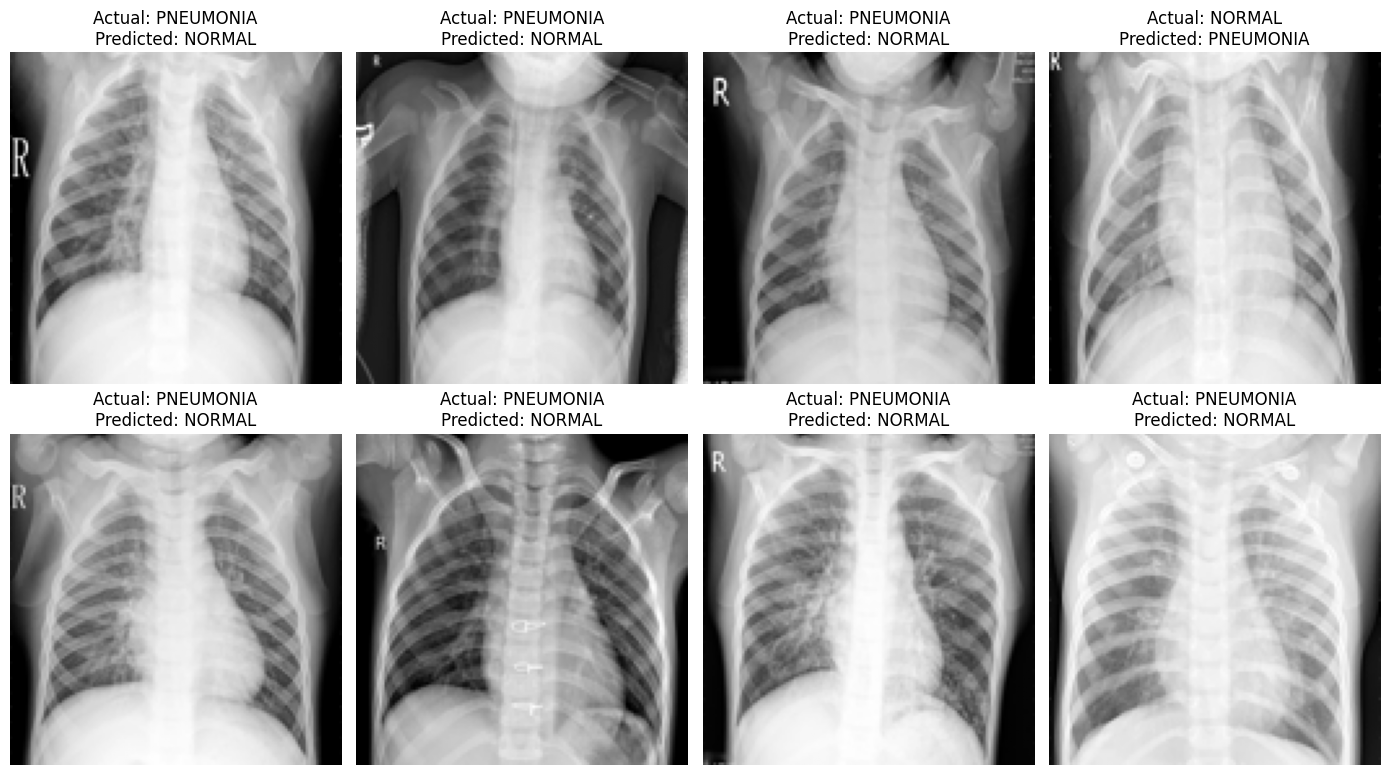

In [27]:
import numpy as np
import matplotlib.pyplot as plt

misclassified = np.where(y_test_img != y_pred)[0]

print("Misclassified images:", len(misclassified))

n = min(8, len(misclassified))
plt.figure(figsize=(14, 8))

for i, idx in enumerate(misclassified[:n]):
    plt.subplot(2, 4, i + 1)
    plt.imshow(X_test_img[idx].squeeze(), cmap="gray")

    actual = "PNEUMONIA" if y_test_img[idx] == 1 else "NORMAL"
    predicted = "PNEUMONIA" if y_pred[idx] == 1 else "NORMAL"

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:

from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import numpy as np

# Check required feature data
if "X_train" not in globals() or "y_train" not in globals():
    raise NameError(
        "X_train or y_train is missing. "
        "Run the earlier HOG/LBP/GLCM feature extraction and split cells."
    )

# Use a stratified subset to keep computation manageable
if len(X_train) > 1800:
    X_cv, _, y_cv, _ = train_test_split(
        X_train,
        y_train,
        train_size=1800,
        stratify=y_train,
        random_state=42
    )
else:
    X_cv, y_cv = X_train, y_train

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=500, random_state=42)
    ),
    "Linear SVM": make_pipeline(
        StandardScaler(),
        LinearSVC(C=1.0, max_iter=3000, random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=80,
        random_state=42,
        n_jobs=-1
    )
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
comparison = []

for name, clf in models.items():
    print("Evaluating:", name)

    scores = cross_validate(
        clf,
        X_cv,
        y_cv,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    comparison.append({
        "Classifier": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "AUROC": scores["test_roc_auc"].mean()
    })

comparison_df = pd.DataFrame(comparison)
comparison_df = comparison_df.sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

print(
    "Best feature-based classifier:",
    comparison_df.iloc[0]["Classifier"]
)


Evaluating: Logistic Regression
Evaluating: Linear SVM
Evaluating: Random Forest


,Classifier,Accuracy,Precision,Recall,F1 Score,AUROC
0,Logistic Regression,0.9356,0.9565,0.9551,0.9558,0.9786
1,Random Forest,0.9211,0.9334,0.9604,0.9467,0.9698
2,Linear SVM,0.8894,0.9761,0.8698,0.9199,0.9684


Best feature-based classifier: Logistic Regression


In [32]:
best_classifier = comparison_df.iloc[0]

print("BEST FEATURE-BASED CLASSIFIER")
print("Name:", best_classifier["Classifier"])
print("Accuracy:", round(best_classifier["Accuracy"], 4))
print("Precision:", round(best_classifier["Precision"], 4))
print("Recall:", round(best_classifier["Recall"], 4))
print("F1 Score:", round(best_classifier["F1 Score"], 4))
print("AUROC:", round(best_classifier["AUROC"], 4))

BEST FEATURE-BASED CLASSIFIER
Name: Logistic Regression
Accuracy: 0.9356
Precision: 0.9565
Recall: 0.9551
F1 Score: 0.9558
AUROC: 0.9786


In [33]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import pandas as pd

# Uses X_cv and y_cv created by your classifier-comparison cell
tuning_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

param_grid = {
    "classifier__C": [0.1, 1.0, 10.0],
    "classifier__class_weight": [None, "balanced"]
}

cv_tuning = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=42
)

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv_tuning,
    n_jobs=1,
    verbose=1,
    refit=True
)

grid_search.fit(X_cv, y_cv)

print("BEST HYPERPARAMETERS")
print(grid_search.best_params_)
print("Best mean cross-validation F1-score:",
      round(grid_search.best_score_, 4))

tuning_results = pd.DataFrame(grid_search.cv_results_)

display(
    tuning_results[
        [
            "param_classifier__C",
            "param_classifier__class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].sort_values("rank_test_score").round(4)
)


Fitting 3 folds for each of 6 candidates, totalling 18 fits
BEST HYPERPARAMETERS
{'classifier__C': 0.1, 'classifier__class_weight': None}
Best mean cross-validation F1-score: 0.9621


,param_classifier__C,param_classifier__class_weight,mean_test_score,std_test_score,rank_test_score
0,0.1,None,0.9621,0.0015,1
1,0.1,balanced,0.9588,0.0028,2
3,1.0,balanced,0.9558,0.0036,3
2,1.0,None,0.9558,0.0029,4
4,10.0,None,0.9206,0.0105,5
5,10.0,balanced,0.9181,0.0075,6
